In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.max_columns = 500

### Загрузим датасет с машинами. Цель - верно восстанавливать для каждой из них цену продажи!

In [2]:
data = pd.read_csv('autos.csv')

data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
data.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [4]:
### Колонка с тергетом - "selling price"

X = data.drop("selling_price", axis=1)
y = data["selling_price"]

### Будем замерять MSLE!
### Поэтому прологарифмируем таргет
### А после оптимизируем MSE

y = y.apply(np.log1p)

In [5]:
### Разделим выборку на трейн и тест!

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

__Задание__ 

Реализуйте свой MeanTargetEncoder с добавленем некоторого шума!

Однажды в лекционном материале, обсуждая счетчики, мы говорили с вами о том, что из-за них модели могут переобучаться. Один из способов бороться с этим - валидировать расчеты среднего таргета (стратегия отложенной выборки / расчеты на кросс-валидации). Но есть еще проще!

Можно просто к значению счетчика добавить случайный шум (зашумить данные)!

Напомним, что рассчитываться новые признаки должны по такой формуле:

$$
g_j = \frac{\sum_{i=1}^{l} y_i[f_j(x) = f_j(x_i)]}{\sum_{i=1}^{l}[f_j(x) = f_j(x_i)]} + C * \epsilon
$$



Пусть шум будет случайной величиной из нормального стандартного распределения, то есть $\epsilon \sim N(0, 1) $, а $ C = 0.006$.

Создавая свой класс-трансформер, наследуйтесь от классов `BaseEstimator, TransformerMixin` из `sklearn.base`. Трансформер не должен модифицировать передаваемую ему выборку inplace, а все необходимые статистики нужно считать только по обучающей выборке в методе `fit`. Ваш трансформер должен принимать при инициализации список из категориальных признаков и список из числовых признаков. 

Если для какого-то признака в тестовой выборке отсутствует значение, трансформер должен поставить там 0.

На выходе должен получиться датасет того же размера с измененными категориальными признаками.

Класс MeanTargetEncoderNoise должен иметь следующую сигнатуру:



In [6]:
from sklearn.base import BaseEstimator, TransformerMixin

class MeanTargetEncoderNoise(BaseEstimator, TransformerMixin):
    def __init__(self, categorical=None, numeric=None, noise_scale=0.006):
        self.categorical = categorical or []
        self.numeric = numeric or []
        self.noise_scale = noise_scale
        self._category_means = {}

    def fit(self, X, y):
        X_fit = X.copy()
        y_fit = y.copy() 

        for col in self.categorical:
            X_fit[col] = X_fit[col].astype(object)
            means = y_fit.groupby(X_fit[col]).mean()
            noise = np.random.normal(0, 1, size=len(means)) * self.noise_scale
            self._category_means[col] = means + noise

        return self

    def transform(self, X):
        X_ = X.copy()
        
        for col in self.categorical:
            X_[col] = X_[col].astype(object)
            X_[col] = X_[col].map(self._category_means[col]).fillna(0.0)
            
        for col in self.numeric:
            X_[col] = pd.to_numeric(X_[col], errors='coerce').fillna(0.0)
            
        return X_

Разделите колонки на вещественные и категориальные. Приведите все категориальные колонки к типу `object`.

Далее применим наш кодировщик к `X_train, X_test`, так же как например мы применяем `StandardScaler`, чтобы проверить работоспособность нашего класса. Установите зерно датчика случайный чисел `np.random.seed(1)`.

После того, как вы изменили обучающую и тестовую выборки, сохраните первые 10 строк полученного промежуточного датафрейма обучающей выборки (`X_train`) в файл в формате csv с сепаратором `;`. Не забудьте индекс. Отправьте полученный файл в форму ниже.

Список колонок которые должны быть в файле для сдачи:
```py
cols = [
    "km_driven",
    "name",
    "year",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]
```

Разделение колонок на категориальные и числовые.

In [7]:
object_cols = ['name', 'year', 'fuel', 'seller_type', 'transmission', 'owner']
num_cols = ['km_driven']

X.head()

,name,year,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,141000,Diesel,Individual,Manual,Second Owner


Реализация класса MeanTargetEncoderNoise.

In [8]:
# from sklearn.base import BaseEstimator, TransformerMixin

# class MeanTargetEncoderNoise(BaseEstimator, TransformerMixin):

#     def __init__(self, categorical, numeric):

#         ### Your code is here

#     def fit(self, X, y):

#         ### Your code is here

#         return self

#     def transform(self, df):

#         ### Your code is here

#         return temp

Проверка работы трансформера.

In [8]:
np.random.seed(1)
transformer = MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)

transformer.fit(X_train, y_train)

train = transformer.transform(X_train)
test = transformer.transform(X_test)

train.head(10)

,name,year,km_driven,fuel,seller_type,transmission,owner
3294,13.483692,13.436559,50000,13.093756,12.615863,13.771135,12.977730
2290,12.117029,11.903115,70000,12.453832,12.615863,13.771135,12.977730
874,12.310456,13.328864,50000,12.453832,12.615863,12.639805,12.977730
1907,12.491443,13.042359,92198,12.453832,13.152824,12.639805,12.463313
3244,12.390906,12.870886,3240,12.453832,12.615863,12.639805,12.463313
1089,12.687432,13.436559,10000,12.453832,13.152824,12.639805,12.977730
3902,11.698702,11.503504,90000,12.453832,12.615863,12.639805,11.878390
2215,11.120678,11.503504,79000,12.453832,12.615863,12.639805,12.463313
3862,13.172879,13.328864,99700,13.093756,12.615863,12.639805,12.977730
705,13.004194,12.241213,124000,13.093756,12.615863,12.639805,12.463313


In [ ]:
# np.random.seed(1)

# # 2. Инициализация и обучение
# transformer = MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)
# transformer.fit(X_train, y_train)

# # 3. Трансформация
# train = transformer.transform(X_train)

# # 4. Восстановление исходного порядка строк, выбор нужных колонок, сброс индекса и срез
# cols = ["km_driven", "name", "year", "fuel", "seller_type", "transmission", "owner"]
# out_path = "autos_transformed.csv"

# final_rows = train.sort_index()[cols].reset_index(drop=True).head(10)

# # 5. Сохранение без записи дублирующей колонки индексов
# final_rows.to_csv('autos_new.csv', sep=';', index=False)

In [ ]:
# train.sort_index().reset_index(drop=True).head(10).to_csv('autos_new.csv', sep=';', index=False)

In [9]:
cols = [
    "km_driven",
    "name",
    "year",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

out_path = "autos_transformed.csv"
train[cols].reset_index(drop=True).head(10).to_csv(out_path, sep=';', index=False)

In [ ]:
# final_rows = train.sort_index().reset_index(drop=True).head(10)
# final_rows

,name,year,km_driven,fuel,seller_type,transmission,owner
0,11.380709,11.825637,70000,12.462321,12.613809,12.638561,12.972476
1,13.124126,12.637051,100000,13.088072,12.627528,12.637310,12.971058
2,12.363807,13.325509,46000,12.451311,12.612979,12.641454,12.964109
3,13.122165,12.929818,141000,13.074978,12.626137,12.634951,12.457642
4,11.614541,11.828866,125000,12.450581,12.619226,12.642518,12.965269
5,12.409114,12.926616,60000,12.447466,12.619048,12.629512,12.462475
6,13.667380,13.053613,25000,12.446102,12.627111,12.642015,12.971835
7,12.811779,13.339001,78000,12.437931,12.618761,12.645986,12.968652
8,12.360100,13.060713,35000,12.456262,12.617969,12.637393,12.975265
9,12.395954,12.928577,100000,12.444904,12.611787,12.645074,12.973026


In [ ]:
# X_test[X_test["name"] == "Maruti Wagon R LXI Minor"].head(10)

,name,year,km_driven,fuel,seller_type,transmission,owner
4022,Maruti Wagon R LXI Minor,2008,90000,Petrol,Individual,Manual,Second Owner
1,Maruti Wagon R LXI Minor,2007,50000,Petrol,Individual,Manual,First Owner
524,Maruti Wagon R LXI Minor,2007,49000,Petrol,Dealer,Manual,First Owner
3468,Maruti Wagon R LXI Minor,2007,60000,Petrol,Individual,Manual,Third Owner
3573,Maruti Wagon R LXI Minor,2008,100000,Petrol,Individual,Manual,Second Owner


Обучите несколько деревьев, перебирая максимальную глубину алгоритма из списка `max_depth_list`, а остальные параметры оставьте дефолтными. Выведите лучшее значение гиперпараметра. Постройте график зависимости MSLE на тестовой выборке от значения гиперпараметра. Воспользуйтесь `Pipeline` без `GridSearch`. Проделайте то же самое с `min_samples_split`, `min_impurity_decrease`, `max_leaf_nodes`.

In [11]:
max_depth_list = [3, 5, 8, 12]
min_samples_split_list = [10, 50, 100, 500]
min_impurity_decrease_list = [0, 0.1, 0.15, 0.2]
max_leaf_nodes_list = [100, 200, 500]

In [12]:
from sklearn.metrics import mean_squared_error as mse
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

np.random.seed(1)

msle_max_depth_list = []
for max_deep in max_depth_list:
    pipe = Pipeline([
        ('encoder', MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
        ('decision_tree', DecisionTreeRegressor(max_depth=max_deep, random_state=1))
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    msle_max_depth_list.append(mse(y_test, y_pred))



In [13]:
msle_min_samples_split_list = []
for min_samples_split in min_samples_split_list:
    pipe = Pipeline([
        ('encoder', MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
        ('decision_tree', DecisionTreeRegressor(min_samples_split=min_samples_split, random_state=1))
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    msle_min_samples_split_list.append(mse(y_test, y_pred))

In [14]:
msle_min_impurity_decrease_list = []
for min_impurity_decrease in min_impurity_decrease_list:
    pipe = Pipeline([
        ('encoder', MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
        ('decision_tree', DecisionTreeRegressor(min_impurity_decrease=min_impurity_decrease, random_state=1))
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    msle_min_impurity_decrease_list.append(mse(y_test, y_pred))

In [15]:
msle_max_leaf_nodes_list = []
for max_leaf_nodes in max_leaf_nodes_list:
    pipe = Pipeline([
        ('encoder', MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
        ('decision_tree', DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes, random_state=1))
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    msle_max_leaf_nodes_list.append(mse(y_test, y_pred))

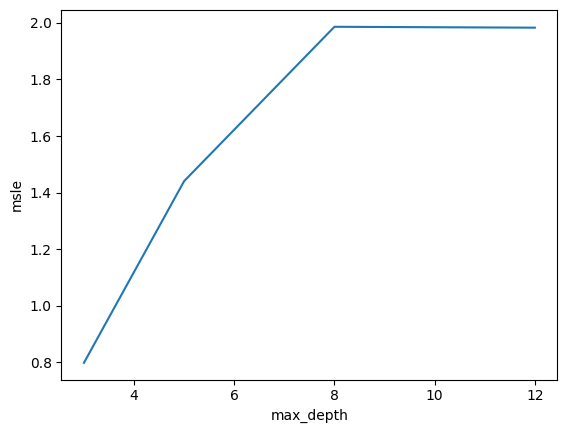

In [16]:
plt.plot(max_depth_list, msle_max_depth_list)
plt.xlabel("max_depth")
plt.ylabel("msle")
plt.show()

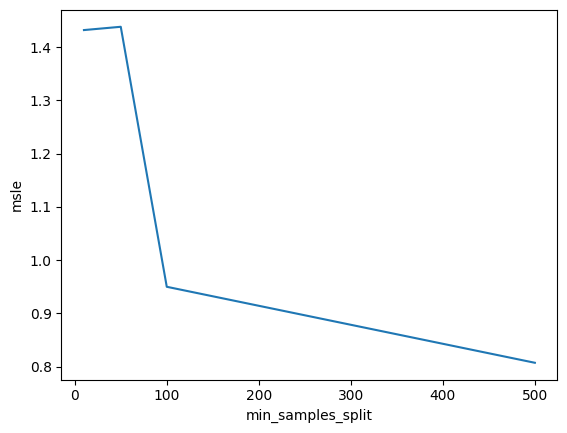

In [17]:
plt.plot(min_samples_split_list, msle_min_samples_split_list)
plt.xlabel("min_samples_split")
plt.ylabel("msle")
plt.show()

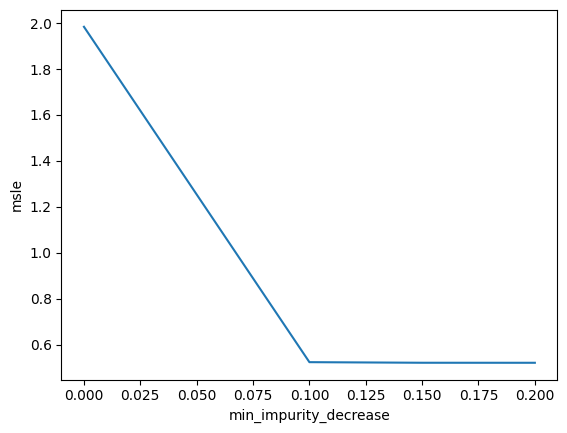

In [18]:
plt.plot(min_impurity_decrease_list, msle_min_impurity_decrease_list)
plt.xlabel("min_impurity_decrease")
plt.ylabel("msle")
plt.show()

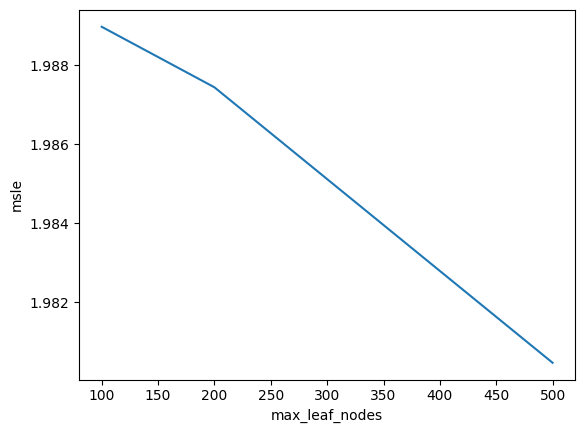

In [19]:
plt.plot(max_leaf_nodes_list, msle_max_leaf_nodes_list)
plt.xlabel("max_leaf_nodes")
plt.ylabel("msle")
plt.show()

In [22]:
min_msle = min(
    min(scores)
    for scores in (
        msle_max_depth_list,
        msle_min_samples_split_list,
        msle_min_impurity_decrease_list,
        msle_max_leaf_nodes_list,
    )
)
min_msle

0.5203671389080692

Подберите лучшую комбинацию параметров, используя `GridSearchCV` и набор массивов значений параметров из предыдущего задания. Для лучшей комбинации посчитайте MSLE на тестовой выборке. Получились ли лучшие параметры такими же, как если бы вы подбирали их по-отдельности при остальных гиперпараметрах по умолчанию (предыдущее задание)? (2б)

In [23]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "decision_tree__max_depth": [3, 5, 8, 12],
    "decision_tree__min_samples_split": [10, 50, 100, 500],
    "decision_tree__min_impurity_decrease": [0, 0.1, 0.15, 0.2],
    "decision_tree__max_leaf_nodes": [100, 200, 500]
}
np.random.seed(1)

### Your code is here


pipe = Pipeline([
        ('encoder', MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
        ('decision_tree', DecisionTreeRegressor(random_state=1))
    ])


grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring="neg_mean_squared_error")
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best score:", -grid_search.best_score_)
print("Best estimator:", grid_search.best_estimator_)
print("Best MSE:", mse(y_test, grid_search.predict(X_test)))

Best parameters: {'decision_tree__max_depth': 3, 'decision_tree__max_leaf_nodes': 100, 'decision_tree__min_impurity_decrease': 0.15, 'decision_tree__min_samples_split': 10}
Best score: 0.5711378321440195
Best estimator: Pipeline(steps=[('encoder',
                 MeanTargetEncoderNoise(categorical=['name', 'year', 'fuel',
                                                     'seller_type',
                                                     'transmission', 'owner'],
                                        numeric=['km_driven'])),
                ('decision_tree',
                 DecisionTreeRegressor(max_depth=3, max_leaf_nodes=100,
                                       min_impurity_decrease=0.15,
                                       min_samples_split=10, random_state=1))])
Best MSE: 0.5203671389080678
